In [99]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Questão 01 a)

$y' = \frac{x² + 1}{y² + 1}$

In [100]:
#Definindo x, y e C como variávies simbólicas
x, y, C = sp.symbols('x y C')

#Separando as funções
lado_esquerdo = (y**2 + 1)
lado_direito = (x**2 + 1)

#Integrando ambos os lados 
integral_y = sp.integrate(lado_esquerdo, y) #Integral em relação a y
integral_x = sp.integrate(lado_direito, x)  #Integral em relação a x

#Criando uma equação com a resposta das integrais
edo1 = sp.Eq(integral_y , integral_x + C)  

print("Resposta: ")
display(edo1)

Resposta: 


Eq(y**3/3 + y, C + x**3/3 + x)

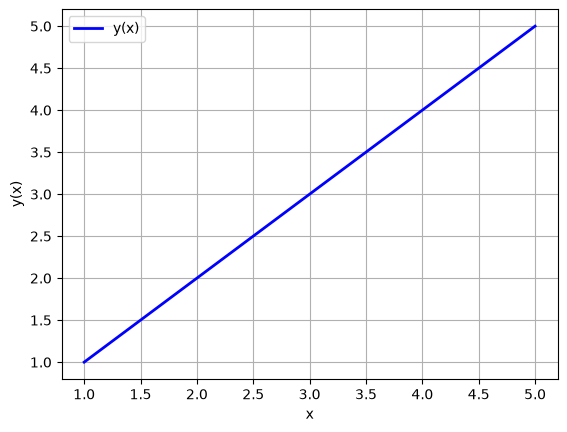

In [ ]:
#Definindo uma função para a equação (x**2 + 1) / (y**2 + 1)
def modelo1(x, y):
    return (x**2 + 1) / (y**2 + 1)

y0_q1 = [1]
intervalo_x1 = (1, 5)
valores_x1 = np.linspace(1, 5, 100)

solucao_num1 = solve_ivp(modelo1, intervalo_x1, y0_q1, t_eval = valores_x1)


plt.Figure(figsize=(8, 5))
plt.plot(solucao_num1.t, solucao_num1.y[0], label="y(x)", color="blue", linewidth=2)

# Adicionando os detalhes estéticos
plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)     # Liga a gra

# b)

$y' = x²-3x²y$

In [102]:
#Definindo x e C como variáveis simbólicas
x, C = sp.symbols('x C')

#Definindo y como variávell dependente de x
y = sp.Function('y')(x)

#Criando uma equação com a resposta das integrais
edo2 = sp.Eq(y.diff(x), x ** 2 - (3*x**2) * y)

#Resolvendo a equação diferencial
resposta2 = sp.dsolve(edo2, y)
display(resposta2)


Eq(y(x), C1*exp(-x**3) + 1/3)

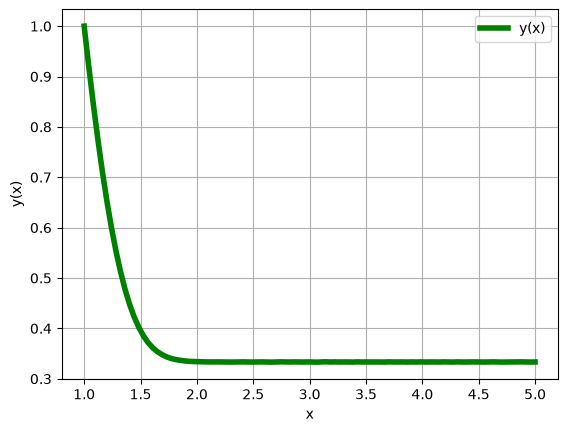

In [ ]:
def modelo2(x, y):
    return (x ** 2 - (3*x**2) * y)

y0_b = [1]
intervalo_xb = (1, 5)
valores_xb = np.linspace(1, 5, 100)

solucao_num2 = solve_ivp(modelo2, intervalo_xb, y0_b, t_eval=valores_xb)


plt.Figure(figsize=(8, 8))
plt.plot(solucao_num2.t, solucao_num2.y[0], label='y(x)', color='green', linewidth=4)

# Adicionando os detalhes estéticos
plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)     # Liga a grade de fundo
plt.legend()       # Mostra a legendap',
plt.show()         # Imprime o gráfico na tela


# c)

$(2xy + cos(x))dx + (x² - 4y)dy = 0$

In [104]:
#Declarando x e y como varáveis simbólicas
x, y = sp.symbols('x y')

M_xy = (2 * x * y + sp.cos(x))  #M(x, y)
N_xy = (x**2 - 4 * y)           #N(x, y)

#Calculando a derivada parcial
dM_dy = sp.diff(M_xy, y)    #Derivada parcial de M em relação a y
dN_dx = sp.diff(N_xy, x)    #Derivada parcial de N em relação a x

print("∂M/∂y =  ", dM_dy)

print("∂N/∂x = ", dN_dx)

if dM_dy == dN_dx:
    print("A equação é exata")
else:
    print("A equação não é exata")


∂M/∂y =   2*x
∂N/∂x =  2*x
A equação é exata


In [105]:
#Integra a N(x, y) em relação a y + g(x)
integral_n = sp.integrate(N_xy, y)

#Calcula a derivada parcial em relação a x
di_dx = sp.diff(integral_n, x)

#encontra o g'(x)
g_prime = sp.simplify(M_xy - di_dx)

#Integra o g'(x) para descobrir a primitiva g(x)
g_z = sp.integrate(g_prime, x)

#Substitui g(x) pelo valor encontrado
eq_complet = sp.simplify(integral_n + g_z)

#Cria a euqação
resposta3 = sp.Eq(eq_complet, C)
display(resposta3)

Eq(x**2*y - 2*y**2 + sin(x), C)

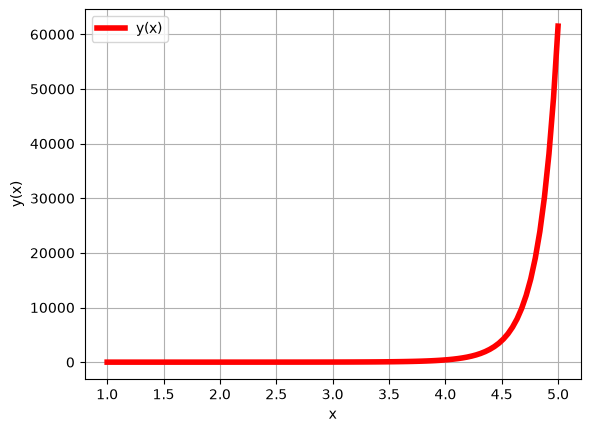

In [106]:
def modelo3(x, y):
        return (2 * x * y + sp.cos(x)) + (x**2 - 4 * y)

y0_c = [1]
intervalo_xc = (1, 5)
valores_xc = np.linspace(1, 5, 100)

solucao_num3 = solve_ivp(modelo3, intervalo_xc, y0_c, t_eval=valores_xb)

plt.Figure(figsize=(8, 8))
plt.plot(solucao_num3.t, solucao_num3.y[0], label='y(x)', color='red', linewidth=4)

# Adicionando os detalhes estéticos
plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)     # Liga a grade de fundo
plt.legend()       # Mostra a legenda
plt.show()         # Imprime o gráfico na tela

# d)
$(x² + y²)dx - xydy = 0$

In [107]:
#Definindo x e C como variaveis simbólicas
x, C = sp.symbols('x C')

#Definindo u como variavel de substituição onde u = y/x
u = sp.Function('u')(x)

substituicao_y = u * x                  #y = u * x
substituicao_dy = u + x * (u.diff(x))   #dy/dx = u + x * du/dx

func = (x**2 + y**2) / (x * y)
#Substituindo y por u * x
func_sub_u = func.subs(y, substituicao_y)
#Simplificando a equação
func_new = sp.sympify(func_sub_u)
#Criando a equação
new_edo = sp.Eq(substituicao_dy, func_new)
resposta4 = sp.dsolve(new_edo, u)

#Convertendo u para y
for sol in resposta4:
    sol_y = sol.rhs * x                
    eq_y = sp.Eq(y, sol_y)
    display(sp.simplify(eq_y))

Eq(y, -x*sqrt(C1 + 2*log(x)))

Eq(y, x*sqrt(C1 + 2*log(x)))

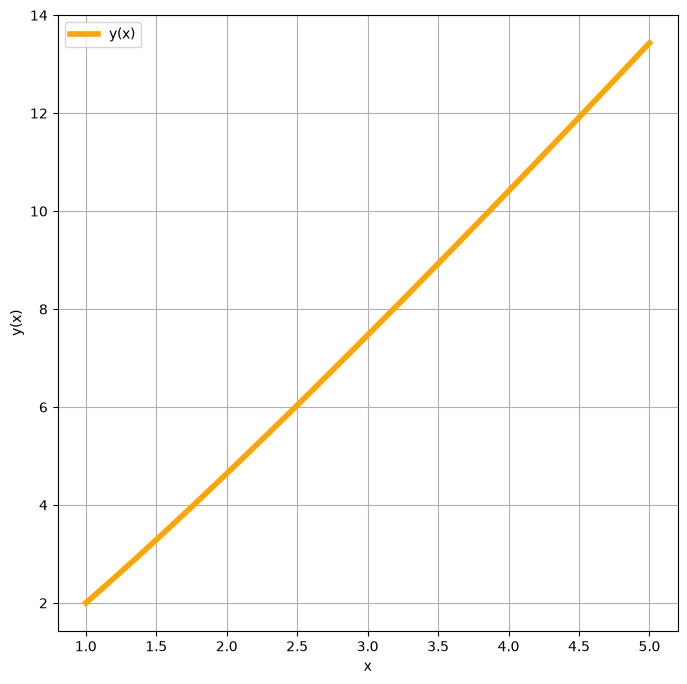

In [108]:
def modelo_d(x, y):
    return (x**2 + y**2) / (x * y)

y0_d = [2]                          
intervalo_xd = (1, 5)                
valores_xd = np.linspace(1, 5, 100)

solucao_num_d = solve_ivp(modelo_d, intervalo_xd, y0_d, t_eval=valores_xd)

plt.figure(figsize=(8, 8))
plt.plot(solucao_num_d.t, solucao_num_d.y[0], label='y(x)', color='orange', linewidth=4)

plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)
plt.legend()
plt.show()

# d)
$y' = (x² + y² - 1)$

In [109]:
#Definindo x e C como variáveis simbólicas
x, C = sp.symbols('x C')

#Definindo y como variável dependente de x
y = sp.Function('y')(x)

#Fazendo a substituição v = x + y - 1 (pois dy/dx = (x+y-1)² não é separável nem exata direto)
#Como v = x + y - 1, então dv/dx = 1 + dy/dx
v = sp.Function('v')(x)

lado_esquerdo = v.diff(x)      #dv/dx
lado_direito = 1 + v**2        #1 + dy/dx, já substituindo dy/dx = v²

#Criando a equação com v (agora ela é separável)
edo3 = sp.Eq(lado_esquerdo, lado_direito)

#Resolvendo a equação diferencial em v
resposta3_v = sp.dsolve(edo3, v)

#Voltando de v para y, já que v = x + y - 1  =>  y = v - x + 1
resposta3_y = sp.Eq(y, resposta3_v.rhs - x + 1)
display(sp.simplify(resposta3_y))

Eq(y(x), -x - tan(C1 - x) + 1)

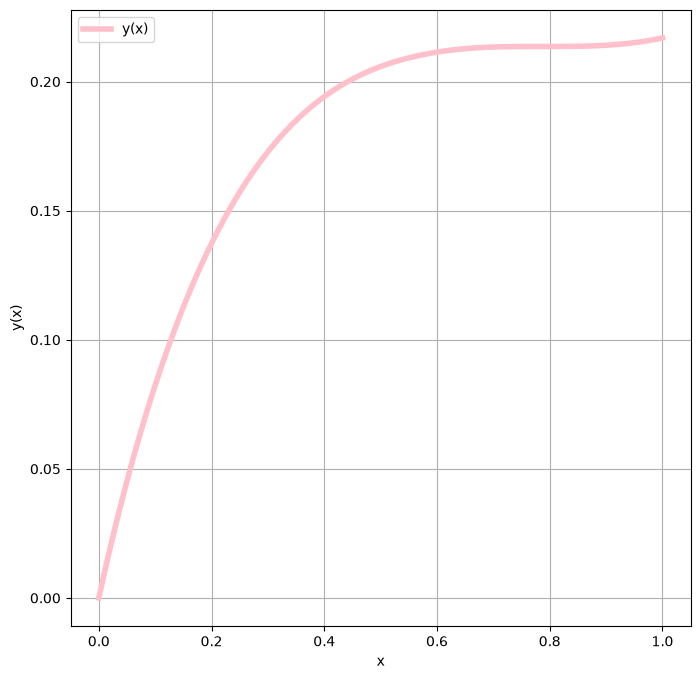

In [110]:
def modelo_e(x, y):
    return (x + y - 1)**2

y0_e = [0]
intervalo_xe = (0, 1)
valores_xe = np.linspace(0, 1, 100)

solucao_num_e = solve_ivp(modelo_e, intervalo_xe, y0_e, t_eval=valores_xe)

plt.figure(figsize=(8, 8))
plt.plot(solucao_num_e.t, solucao_num_e.y[0], label='y(x)', color='pink', linewidth=4)

plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)
plt.legend()
plt.show()

# Questão 02 

$y' = 3y^\frac{2}{3}$

In [113]:
#Definindo x e c como variaveis simbólicas
x, C = sp.symbols('x C')

#Definindo y como variavel dependente de x
y = sp.Function('y')(x)

#Criando a euqação
edo6 = sp.Eq(y.diff(x), 3 * y ** sp.Rational(2, 3))

#Resolvendo a EDO
reposta6 = sp.dsolve(edo6, y)
display(reposta6)

Eq(y(x), C1**3/27 + C1**2*x/3 + C1*x**2 + x**3)

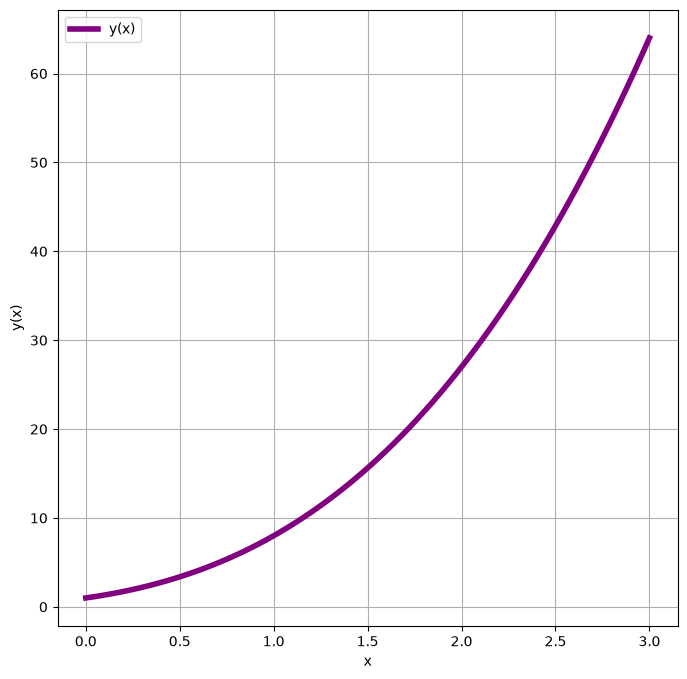

In [115]:
def modelo6(x, y):
    return 3 * y**(2/3)

y0_6 = [1]
intervalo_x6 = (0, 3)
valores_x6 = np.linspace(0, 3, 100)

solucao_num6 = solve_ivp(modelo6, intervalo_x6, y0_6, t_eval=valores_x6)

plt.figure(figsize=(8, 8))
plt.plot(solucao_num6.t, solucao_num6.y[0], label='y(x)', color='purple', linewidth=4)

plt.xlabel("x")
plt.ylabel("y(x)")
plt.grid(True)
plt.legend()

plt.show()